# Create Training Features for CS

This notebook creates training features for Continental Shelf (CS) regions.
It processes sediment rate labels and extracts features from the Restrepo dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from os import walk
from pathlib import Path
from shapely.geometry import Point
import geopandas as gpd
from geopandas import GeoDataFrame
import sys
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')

# Get project root and add to path
project_root = Path().resolve().parents[0] if Path().resolve().name == 'notebooks' else Path().resolve()
if project_root.name != 'mtl-mar':
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))
from utils import DATA_RAW, DATA_INTERIM

In [2]:
def find_nearest(value, vector):
    """Find the index of the nearest value in a vector."""
    vector = np.float64(vector) - np.float64(value)
    return np.argmin(np.abs(vector))

## Load Sediment Rate Labels

Load the sediment rate labels from the deep sea dataset.

In [3]:
data_path = DATA_RAW / "labels"
sed_labels_file = "sedrate_continentalshelves.csv"

df = pd.read_csv(Path(data_path / sed_labels_file))

## Preprocess Labels
Filter and clean the sediment rate labels, then visualize the data distribution.

Total number of samples: 10836


,Latitude,Longitude,MAR(g/cm**2/ka)
count,10836.000000,10836.000000,10836.000000
mean,25.291575,95.849764,218.470338
std,18.950500,61.373172,304.851022
min,-72.875000,-179.458333,0.000000
25%,10.892552,102.664051,10.000000
50%,27.552345,121.754941,140.400000
75%,30.289815,123.752201,210.600000
max,81.857694,179.458333,5070.000000


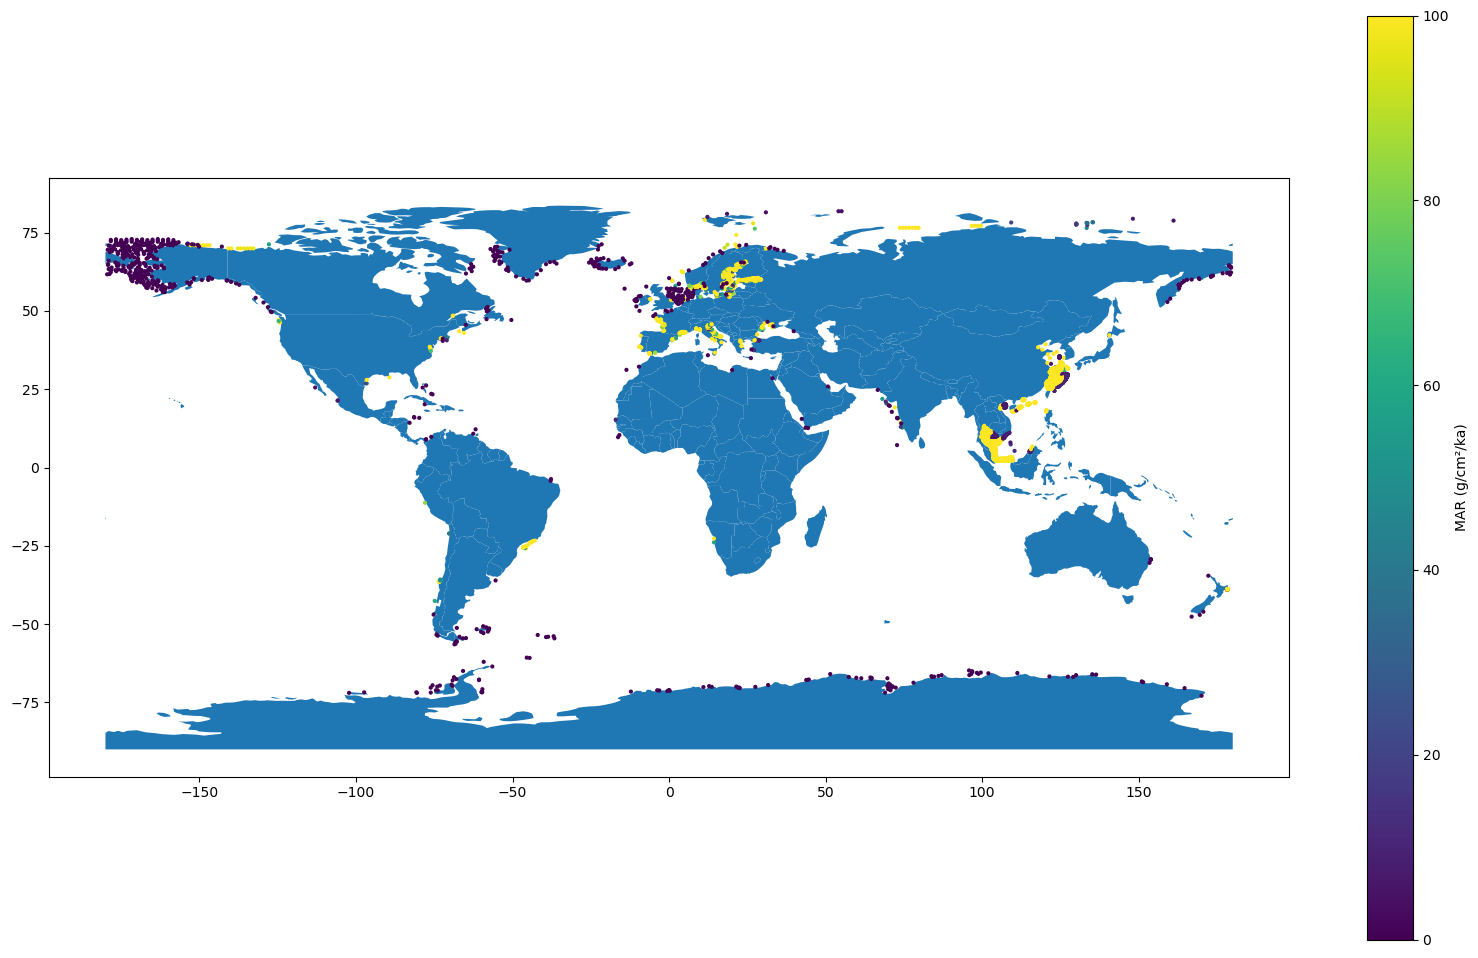

In [4]:
# Select relevant columns and filter data
df = df[["Latitude", "Longitude", "MAR(g/cm**2/ka)"]]
df = df[df["Longitude"] > -180]
df = df.dropna(how="any")

# Visualize data distribution
try:
    world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
except:
    # Fallback if geopandas dataset is unavailable
    world = None

geometry = [Point(xy) for xy in zip(df['Longitude'], df['Latitude'])]
gdf = GeoDataFrame(df, geometry=geometry)

if world is not None:
    gdf.plot(ax=world.plot(figsize=(20, 12)), 
             column=df["MAR(g/cm**2/ka)"], 
             vmin=0, vmax=100,
             legend=True, 
             legend_kwds={"label": "MAR (g/cm²/ka)"}, 
             markersize=4)

print(f"Total number of samples: {len(df)}")
df.describe()

## Load Feature Files

Load the list of available feature files from the Restrepo dataset.



In [5]:
restrepo_features_path = DATA_RAW / "features" / "FeaturesPhrampusLee_TOCSedRate_updated"
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    restrepo_files.extend(filenames)

restrepo_files.sort()
print(f"Total feature files found: {len(restrepo_files)}")

Total feature files found: 510


## Select Features

Filter feature files based on a predefined selection list.

In [6]:
# Load feature selection list
# header=None: first line is a feature filename, not a CSV column name
feature_selection = pd.read_csv(DATA_INTERIM / "selectedFeatureLists" / "selectedfeatures_v_men.txt", header=None).values.flatten()

# Filter files to only include selected features
selected_files = []
for file in restrepo_files:
    if file in feature_selection:
        selected_files.append(file)

print(f"Selected {len(selected_files)} features from {len(restrepo_files)} available files")
restrepo_files = selected_files

Selected 111 features from 510 available files


## Extract Features

Extract feature values at the locations of sediment rate measurements. Features are extracted from NetCDF files using nearest-neighbor interpolation on a 5 arc-minute grid.

In [7]:
# Initialize feature arrays
restrepo_features = np.empty([len(df), len(restrepo_files)])
restrepo_features[:] = np.nan
restrepo_X_mean = np.empty(0)
restrepo_X_std = np.empty(0)

# Create latitude and longitude arrays for 5 arc-minute grid
# 5 arc minutes = 5/60 = 0.0833333 degrees
latitudes = np.linspace(-90, 90, 2160)
longitudes = np.linspace(-180, 180, 4320)

# Pre-compute indices for all data points
lat_idx = []
lon_idx = []
for data_idx in range(len(df)):
    lat_idx.append(find_nearest(df.iloc[data_idx, 0], latitudes))
    lon_idx.append(find_nearest(df.iloc[data_idx, 1], longitudes))

# Extract features from each file
file_idx = -1
corrupted_files = 0

for file in restrepo_files:
    file_idx += 1
    try:
        rootgrp = xr.open_dataset(Path(restrepo_features_path / file), format='NETCDF4')
    except Exception as e:
        restrepo_X_mean = np.append(restrepo_X_mean, np.nan)
        restrepo_X_std = np.append(restrepo_X_std, np.nan)
        corrupted_files += 1
        print(f"Warning: Could not load {file}: {e}")
        continue

    dataset = rootgrp.variables['data']
    
    # Compute global statistics
    restrepo_X_mean = np.append(restrepo_X_mean, np.nanmean(dataset))
    restrepo_X_std = np.append(restrepo_X_std, np.nanstd(dataset))
    
    # Special handling for elevation: remove points with elevation > 5 m
    # (these are likely mislocated points, especially in Middle East regions)
    if file == "GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd":
        for data_idx in range(len(df)):
            elev_value = dataset[lat_idx[data_idx], lon_idx[data_idx]]
            if elev_value > 5:
                restrepo_features[data_idx, file_idx] = np.nan
            else:
                restrepo_features[data_idx, file_idx] = elev_value
    else:
        # Extract feature values for all data points
        for data_idx in range(len(df)):
            restrepo_features[data_idx, file_idx] = dataset[lat_idx[data_idx], lon_idx[data_idx]]
    
    if (file_idx + 1) % 10 == 0:
        print(f"Processed {file_idx + 1}/{len(restrepo_files)} files...")

print(f"\nFeature extraction complete!")
print(f"Corrupted files: {corrupted_files}")
print(f"Feature matrix shape: {restrepo_features.shape}")

Processed 10/111 files...


Processed 20/111 files...


Processed 30/111 files...


Processed 40/111 files...


Processed 50/111 files...


Processed 60/111 files...


... (2 outputs left out)

Processed 90/111 files...


Processed 100/111 files...


Processed 110/111 files...



Feature extraction complete!
Corrupted files: 0
Feature matrix shape: (10836, 111)


## Save Features and Labels

Save the extracted features, labels, and statistics to disk for model training.

In [8]:
# Prepare save path
save_path = DATA_INTERIM / "inputfeatures" / "SedTOCFeaturesnoNAN_MAR_CS_men"
save_path.mkdir(parents=True, exist_ok=True)

# Save features, labels, and statistics
np.save(Path(save_path / "numpy_features"), restrepo_features)
np.save(Path(save_path / "numpy_labels"), df["MAR(g/cm**2/ka)"].values)
np.save(Path(save_path / "numpy_lat"), np.array(df["Latitude"]))
np.save(Path(save_path / "numpy_lon"), np.array(df["Longitude"]))
np.save(Path(save_path / "features_mean"), restrepo_X_mean)
np.save(Path(save_path / "features_std"), restrepo_X_std)
with open(save_path / "feature_files.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(restrepo_files))

print(f"All data saved to: {save_path}")
print(f"Features shape: {restrepo_features.shape}")
print(f"Labels shape: {df['MAR(g/cm**2/ka)'].values.shape}")
print(f"Feature count: {len(restrepo_files)} (see selectedFeatureLists/extrapolated_features_metadata.csv)")

All data saved to: /gxfs_work/cau/sunms498/work/mtl-mar/data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_CS_men
Features shape: (10836, 111)
Labels shape: (10836,)
Feature count: 111 (see selectedFeatureLists/extrapolated_features_metadata.csv)
